<a href="https://colab.research.google.com/github/waltergsotelo/aprendizaje_profundo/blob/main/TP_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import random
from pathlib import Path

os.environ.setdefault("NUMBA_CACHE_DIR", str(Path.cwd() / ".numba_cache"))

import numba
numba.config.CACHE_DIR = os.environ["NUMBA_CACHE_DIR"]

import numpy as np
import librosa
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Verificar si hay GPU disponible
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Usando dispositivo: {device}")

Usando dispositivo: mps


## Hacemos la descarga los de los archivo .wav separados por carpeta segun el genero

In [2]:
import gdown
import zipfile
import os
from pathlib import Path

url = "https://drive.google.com/uc?id=1txyVxGVezQ4fcHqFi-n3gcWKEYQexu1_"
output = "dataset_music.zip"

if Path(output).exists():
    print(f"Usando archivo existente: {output}")
else:
    gdown.download(url, output, quiet=False)

destino = "datos_music"
os.makedirs(destino, exist_ok=True)

with zipfile.ZipFile(output, "r") as zip_ref:
    zip_ref.extractall(destino)

DATASET_PATH = Path.cwd() / destino / "genres_original"

Usando archivo existente: dataset_music.zip


### Vamos a separa los archivos de cada estilo musical en un 80/20 para training/test

In [3]:
from pathlib import Path
from sklearn.model_selection import train_test_split

data_dir = Path(DATASET_PATH)
if not data_dir.is_dir():
    raise FileNotFoundError(f"No se encontró el directorio del dataset: {data_dir}")

genre_files = [
    (genre_dir.name, sorted(genre_dir.glob("*.wav")))
    for genre_dir in sorted(data_dir.iterdir())
    if genre_dir.is_dir()
]
genre_files = [(genre, wav_files) for genre, wav_files in genre_files if wav_files]
if not genre_files:
    raise FileNotFoundError(f"No se encontraron archivos WAV en: {data_dir}")

class_names = [genre for genre, _ in genre_files]
class_to_idx = {class_name: i for i, class_name in enumerate(class_names)}
audio_paths = []
labels = []

print(f"Géneros detectados: {class_names}")

for genre, wav_files in genre_files:
    for audio_path in wav_files:
        audio_paths.append(str(audio_path))
        labels.append(class_to_idx[genre])

print(f"Total de archivos encontrados: {len(audio_paths)}")

# 3. Hacer la partición 80% entrenamiento / 20% validación (con estratificación para mantener proporciones)
train_paths, val_paths, train_labels, val_labels = train_test_split(
    audio_paths,
    labels,
    test_size=0.20,      # 20% para validación
    random_state=42,     # Semilla para que la división sea reproducible
    stratify=labels      # Asegura que cada género tenga el mismo % en train y val
)

print(f"Archivos de Entrenamiento: {len(train_paths)}")
print(f"Archivos de Validación: {len(val_paths)}")

Géneros detectados: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
Total de archivos encontrados: 999
Archivos de Entrenamiento: 799
Archivos de Validación: 200


Extrayendo características acústicas de los audios...


  0%|          | 0/999 [00:00<?, ?it/s]/opt/homebrew/Caskroom/miniforge/base/envs/vision-cv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
100%|██████████| 999/999 [02:57<00:00,  5.64it/s]


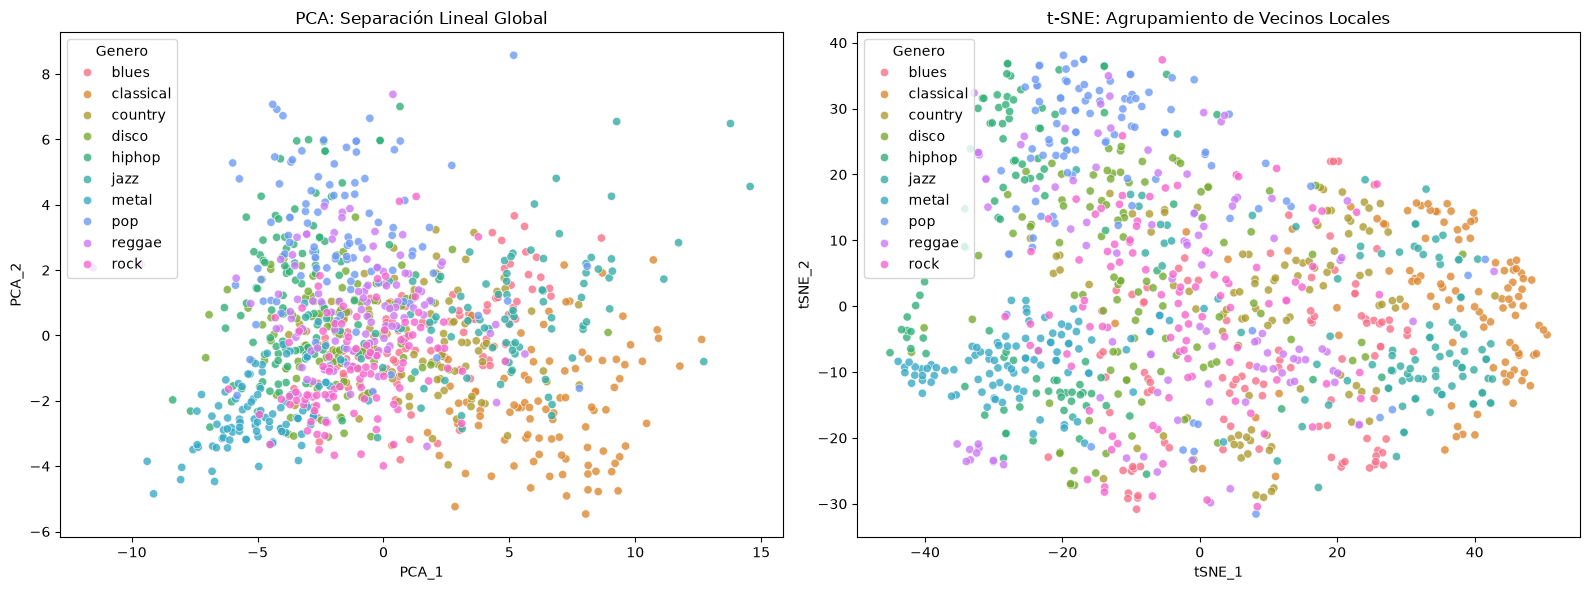

In [4]:
import os
from pathlib import Path

os.environ.setdefault("NUMBA_CACHE_DIR", str(Path.cwd() / ".numba_cache"))

import numba
numba.config.CACHE_DIR = os.environ["NUMBA_CACHE_DIR"]

import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

def build_audio_index(dataset_path):
    data_dir = Path(dataset_path)
    if not data_dir.is_dir():
        raise FileNotFoundError(f"No se encontró el directorio del dataset: {data_dir}")

    genre_dirs = [
        genre_dir
        for genre_dir in sorted(data_dir.iterdir())
        if genre_dir.is_dir() and any(genre_dir.glob("*.wav"))
    ]
    if not genre_dirs:
        raise FileNotFoundError(f"No se encontraron archivos WAV en: {data_dir}")

    class_names = [genre_dir.name for genre_dir in genre_dirs]
    audio_paths = []
    labels = []
    for class_index, genre_dir in enumerate(genre_dirs):
        wav_files = sorted(genre_dir.glob("*.wav"))
        audio_paths.extend(str(audio_file) for audio_file in wav_files)
        labels.extend([class_index] * len(wav_files))

    return audio_paths, labels, class_names

dataset_path = globals().get(
    "DATASET_PATH", Path.cwd() / "datos_music" / "genres_original"
)
audio_paths, labels, class_names = build_audio_index(dataset_path)

# 1. Extracción de características matemáticas
datos = []

print("Extrayendo características acústicas de los audios...")
for path, label in tqdm(zip(audio_paths, labels), total=len(audio_paths)):
    try:
        # Cargar audio
        y, sr = librosa.load(path, sr=22050, duration=30)
        
        # Extraer características base
        zcr = librosa.feature.zero_crossing_rate(y)
        centroid = librosa.feature.spectral_centroid(y=y, sr=sr)
        bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr)
        tempo, _ = librosa.beat.beat_track(y=y, sr=sr)
        chroma = librosa.feature.chroma_stft(y=y, sr=sr)
        contrast = librosa.feature.spectral_contrast(y=y, sr=sr)
        # 1. Extracción de los nuevos contornos temporales
        tonnetz = librosa.feature.tonnetz(y=y, sr=sr, chroma=chroma) # Aprovecha el chroma ya calculado
        rms = librosa.feature.rms(y=y)
        zcr = librosa.feature.zero_crossing_rate(y=y)
        rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr,roll_percent=0.85)
                
        # Promediar las características a lo largo del tiempo
        zcr_mean = np.mean(zcr)
        centroid_mean = np.mean(centroid)
        bandwidth_mean = np.mean(bandwidth)
        chroma_mean = np.mean(chroma, axis=1)
        chroma_var = np.var(chroma, axis=1)
        contrast_mean = np.mean(contrast, axis=1)
        contrast_var = np.var(contrast, axis=1)
        tonnetz_mean = np.mean(tonnetz, axis=1)
        tonnetz_var = np.var(tonnetz, axis=1)
        rms_mean = float(np.mean(rms))
        rms_var = float(np.var(rms))
        zcr_var = float(np.var(zcr))
        rolloff_mean = float(np.mean(rolloff))
        rolloff_var = float(np.var(rolloff))

        
        # Manejo de la variable tempo (dependiendo de la versión de librosa puede ser array o float)
        bpm = tempo[0] if isinstance(tempo, np.ndarray) else tempo
        
        # Obtener el nombre del género en texto
        genero_texto = class_names[label]
        
        # Guardar en la lista
        datos.append([
            zcr_mean,
            centroid_mean,
            bandwidth_mean,
            *chroma_mean,
            *chroma_var,
            *contrast_mean,
            *contrast_var,
            *tonnetz_mean,
            *tonnetz_var,
            rms_mean,
            rms_var,
            zcr_var,
            rolloff_mean,
            rolloff_var,
            float(np.asarray(bpm).reshape(-1)[0]),
            genero_texto,
        ])
        
    except Exception as e:
        print(f"Error procesando {path}: {e}")

# 2. Creación del Dataset Tabular
columnas = ['ZCR', 'Centroide_Espectral', 'Ancho_Banda']
columnas.extend([f'Chroma_{i}_mean' for i in range(1, 13)])
columnas.extend([f'Chroma_{i}_var' for i in range(1, 13)])
columnas.extend([f'Contrast_{i}_mean' for i in range(1, 8)])
columnas.extend([f'Contrast_{i}_var' for i in range(1, 8)])
columnas.extend([f'Tonnetz_{i}_mean' for i in range(1, 7)])
columnas.extend([f'Tonnetz_{i}_var' for i in range(1, 7)])
columnas.extend(['RMS_mean', 'RMS_var', 'ZCR_var', 'Rolloff_mean', 'Rolloff_var'])
columnas.append('BPM')
columnas.append('Genero')



df = pd.DataFrame(datos, columns=columnas)

# Separar las variables independientes (X) de la variable objetivo (y)
X = df.drop('Genero', axis=1)
y_genero = df['Genero']

# 3. Escalado de Datos (Crucial para PCA y t-SNE)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Reducción de Dimensionalidad
# PCA (Mantiene estructura global)
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X_scaled)
df['PCA_1'] = pca_result[:, 0]
df['PCA_2'] = pca_result[:, 1]

# t-SNE (Mantiene estructura local / agrupa vecinos más cercanos)
# perplexity = min(30, numero_de_muestras - 1) para evitar errores en datasets muy chicos
tsne = TSNE(n_components=2, perplexity=min(30, len(df)-1), random_state=42)
tsne_result = tsne.fit_transform(X_scaled)
df['tSNE_1'] = tsne_result[:, 0]
df['tSNE_2'] = tsne_result[:, 1]

# 5. Visualización
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico PCA
sns.scatterplot(
    x='PCA_1', y='PCA_2',
    hue='Genero',
    palette=sns.color_palette("husl", len(class_names)),
    data=df,
    legend="full",
    alpha=0.8,
    ax=axes[0]
)
axes[0].set_title('PCA: Separación Lineal Global')

# Gráfico t-SNE
sns.scatterplot(
    x='tSNE_1', y='tSNE_2',
    hue='Genero',
    palette=sns.color_palette("husl", len(class_names)),
    data=df,
    legend="full",
    alpha=0.8,
    ax=axes[1]
)
axes[1].set_title('t-SNE: Agrupamiento de Vecinos Locales')

plt.tight_layout()
plt.show()

In [5]:
import librosa
import numpy as np
import torch
from torch.utils.data import Dataset

class MultiBranchAudioDataset(Dataset):
    def __init__(self, audio_paths, labels, sr=22050, duration=30, max_time_frames=1300, augment=False):
        self.audio_paths = audio_paths
        self.labels = labels
        self.sr = sr
        self.duration = duration
        self.max_time_frames = max_time_frames
        self.augment = augment

    def __len__(self):
        return len(self.audio_paths)

    def __getitem__(self, idx):
        audio_path = self.audio_paths[idx]
        label = self.labels[idx]

        try:
            y, sr = librosa.load(audio_path, sr=self.sr, duration=self.duration)
            
            # Forzar los mismos parámetros para garantizar que los frames temporales coincidan
            hop_length = 512
            n_fft = 2048

            # --- RAMA 1: MEL (128 bandas) ---
            mel_spec = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=128)
            mel_db = librosa.power_to_db(mel_spec, ref=np.max)
            mel_db = (mel_db - mel_db.mean()) / (mel_db.std() + 1e-6)
            
            mel_stack = np.stack([
                mel_db,
                librosa.feature.delta(mel_db),
                librosa.feature.delta(mel_db, order=2)
            ])

            # --- RAMA 2: CHROMA + CONTRASTE + FEATURES EXTRA (28 bandas) ---
            chroma = librosa.feature.chroma_stft(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length)
            contrast = librosa.feature.spectral_contrast(y=y, sr=sr, n_fft=n_fft, hop_length=hop_length)
            
            chroma = (chroma - chroma.mean()) / (chroma.std() + 1e-6)
            contrast = (contrast - contrast.mean()) / (contrast.std() + 1e-6)

            # 1. Extracción de los nuevos contornos temporales
            tonnetz = librosa.feature.tonnetz(y=y, sr=sr, chroma=chroma) # Aprovecha el chroma ya calculado
            rms = librosa.feature.rms(y=y, hop_length=hop_length)
            zcr = librosa.feature.zero_crossing_rate(y=y, hop_length=hop_length)
            rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr, hop_length=hop_length, roll_percent=0.85)

            # 2. Normalización estandarizada (Crucial al mezclar distintas unidades)
            tonnetz = (tonnetz - tonnetz.mean()) / (tonnetz.std() + 1e-6)
            rms = (rms - rms.mean()) / (rms.std() + 1e-6)
            zcr = (zcr - zcr.mean()) / (zcr.std() + 1e-6)
            rolloff = (rolloff - rolloff.mean()) / (rolloff.std() + 1e-6)
            
            cc_combined = np.concatenate((chroma, contrast, tonnetz, rms, zcr, rolloff), axis=0)
            cc_stack = np.stack([
                cc_combined,
                librosa.feature.delta(cc_combined),
                librosa.feature.delta(cc_combined, order=2)
            ])

            # --- AJUSTE TEMPORAL PARA AMBAS RAMAS ---
            current_frames = mel_stack.shape[-1]
            if current_frames < self.max_time_frames:
                pad_width = self.max_time_frames - current_frames
                # ((0,0) canales, (0,0) bandas, (0, pad_width) tiempo)
                mel_stack = np.pad(mel_stack, ((0, 0), (0, 0), (0, pad_width)), mode='constant')
                cc_stack = np.pad(cc_stack, ((0, 0), (0, 0), (0, pad_width)), mode='constant')
            else:
                mel_stack = mel_stack[:, :, :self.max_time_frames]
                cc_stack = cc_stack[:, :, :self.max_time_frames]

            mel_tensor = torch.tensor(mel_stack, dtype=torch.float32)
            cc_tensor = torch.tensor(cc_stack, dtype=torch.float32)

            if self.augment:
                # Aplicar la misma máscara temporal a ambas ramas.
                time_width = min(64, self.max_time_frames)
                time_start = torch.randint(
                    0, self.max_time_frames - time_width + 1, (1,)
                ).item()
                mel_tensor[:, :, time_start:time_start + time_width] = 0
                cc_tensor[:, :, time_start:time_start + time_width] = 0

                # Enmascarar bandas de frecuencia por separado en cada rama.
                mel_width = min(8, mel_tensor.shape[1])
                mel_start = torch.randint(
                    0, mel_tensor.shape[1] - mel_width + 1, (1,)
                ).item()
                mel_tensor[:, mel_start:mel_start + mel_width, :] = 0

                cc_width = min(4, cc_tensor.shape[1])
                cc_start = torch.randint(
                    0, cc_tensor.shape[1] - cc_width + 1, (1,)
                ).item()
                cc_tensor[:, cc_start:cc_start + cc_width, :] = 0

            return (
                mel_tensor,
                cc_tensor,
                torch.tensor(label, dtype=torch.long)
            )

        except Exception as e:
            print(f"Error procesando {audio_path}: {e}")
            # Retornar tensores de ceros con las dimensiones exactas para no romper el Batch
            return (
                torch.zeros((3, 128, self.max_time_frames)), 
                torch.zeros((3, 28, self.max_time_frames)), 
                torch.tensor(0, dtype=torch.long)
            )

In [6]:
class TemporalAttention(nn.Module):
    def __init__(self, hidden_dim):
        super(TemporalAttention, self).__init__()
        self.attention_weights = nn.Linear(hidden_dim, 1)

    def forward(self, rnn_out):
        # rnn_out shape: [Batch, Time_Frames, Hidden_Dim]
        scores = self.attention_weights(rnn_out) # [Batch, Time_Frames, 1]
        weights = F.softmax(scores, dim=1)        # [Batch, Time_Frames, 1]

        # Suma ponderada temporal (Context Vector)
        context_vector = torch.sum(rnn_out * weights, dim=1) # [Batch, Hidden_Dim]
        return context_vector, weights

import torch
import torch.nn as nn

class MusicGenreCRNN_MultiBranch(nn.Module):
    def __init__(self, num_classes=10, dropout=0.2):
        super().__init__()
        
        # --- RAMA 1: Procesador del Espectrograma Mel (Entrada: 3 x 128 x Time) ---
        self.mel_cnn = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d((2, 2)), # Frecuencia: 128 -> 64 | Tiempo / 2
            
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d((2, 2)), # Frecuencia: 64 -> 32 | Tiempo / 4
            
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d((2, 2)), # Frecuencia: 32 -> 16 | Tiempo / 8
        )
        # Salida Mel aplanada: 128 canales * 16 bandas = 2048 características
        
        # --- RAMA 2: Procesador de Chroma, Contraste y features extra (3 x 28 x Time) ---
        self.cc_cnn = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d((2, 2)), # Bandas: 28 -> 14 | Tiempo / 2
            
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d((2, 2)), # Bandas: 14 -> 7 | Tiempo / 4
            
            # Reducir solo tiempo en esta etapa para preservar las bandas restantes.
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d((1, 2)), # Bandas: 7 -> 7 | Tiempo / 8
        )
        # Con 28 bandas de entrada, la rama CC sale con 64 canales * 7 bandas.
        
        # --- FUSIÓN TARDÍA Y RNN ---
        self.rnn_input_size = 2048 + (64 * 7) # Mel: 2048; CC: 448; total: 2496.
        
        self.rnn = nn.GRU(
            input_size=self.rnn_input_size,
            hidden_size=128,
            num_layers=2,
            batch_first=True,
            dropout=dropout,
            bidirectional=True
        )
        
        self.attention = TemporalAttention(hidden_dim=256)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(256, num_classes)
        
    def forward(self, mel_input, cc_input):
        batch_size = mel_input.size(0)
        
        # 1. Pasar datos por sus respectivas ramas
        mel_out = self.mel_cnn(mel_input) # [Batch, 128, 16, Reduced_Time]
        cc_out = self.cc_cnn(cc_input)    # [Batch, 64, 7, Reduced_Time]
        
        # 2. Reordenar y aplanar para la RNN [Batch, Reduced_Time, Features]
        mel_out = mel_out.permute(0, 3, 1, 2).reshape(batch_size, mel_out.size(3), -1) 
        cc_out = cc_out.permute(0, 3, 1, 2).reshape(batch_size, cc_out.size(3), -1)
        
        # 3. Concatenar en la dimensión de características (Eje 2)
        # Ahora el modelo tiene la textura (Mel) y la armonía (Chroma/Contraste) perfectamente alineadas en el tiempo
        combined_features = torch.cat((mel_out, cc_out), dim=2) 
        
        # 4. Procesamiento temporal y clasificación
        rnn_out, _ = self.rnn(combined_features) 
        context_vector, attention_weights = self.attention(rnn_out)
        out = self.fc(self.dropout(context_vector))
        
        return out, attention_weights

In [7]:
# --- CONFIGURACIÓN REAL CON TUS ARCHIVOS .WAV ---

# 1. Crear los Datasets usando los splits 80/20 que hicimos antes
train_dataset = MultiBranchAudioDataset(audio_paths=train_paths, labels=train_labels, augment=True)
val_dataset = MultiBranchAudioDataset(audio_paths=val_paths, labels=val_labels)

# 2. Crear los DataLoaders (shufle=True solo para entrenamiento)
train_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=0, generator=train_generator)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=0)

# 3. Instanciar modelo, función de pérdida y optimizador
num_genres = len(class_names)  # Se adapta automáticamente a cuántas carpetas/géneros tengas
model = MusicGenreCRNN_MultiBranch(num_classes=num_genres, dropout=0.2).to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print(f"¡Modelo inicializado con éxito para {num_genres} géneros: {class_names}!")
print(f"Lotes de entrenamiento: {len(train_loader)} | Lotes de validación: {len(val_loader)}")

¡Modelo inicializado con éxito para 10 géneros: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']!
Lotes de entrenamiento: 100 | Lotes de validación: 25


In [8]:
# --- OPTIMIZACIÓN DEL PROCESO DE ENTRENAMIENTO PARA LA RED MEJORADA ---

# Usamos AdamW (Adam con Weight Decay) para regularizar los pesos del extractor residual
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)

# Scheduler dinámico: Reduce el LR por un factor de 0.5 si la pérdida de validación no mejora en 3 épocas
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=3,
    cooldown=1,
    min_lr=1e-5,
)

print("⚙️ Optimizador AdamW y Scheduler ReduceLROnPlateau configurados con éxito.")

⚙️ Optimizador AdamW y Scheduler ReduceLROnPlateau configurados con éxito.


In [9]:
import time

num_epochs = 40
best_val_accuracy = 0.0
best_val_loss = float("inf")
early_stopping_patience = 10
epochs_without_improvement = 0

# Historial para graficar
train_loss_history = []
val_loss_history = []
train_acc_history = []
val_acc_history = []

print(f"🚀 Iniciando entrenamiento optimizado por {num_epochs} épocas con Scheduler...")

for epoch in range(num_epochs):
    start_time = time.time()

    # ==========================
    # 1. FASE DE ENTRENAMIENTO
    # ==========================
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for mel_inputs, cc_inputs, labels in train_loader:
        mel_inputs = mel_inputs.to(device)
        cc_inputs = cc_inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs, _ = model(mel_inputs, cc_inputs)
        loss = criterion(outputs, labels)
        loss.backward()

        # Gradient clipping para estabilizar el entrenamiento de la LSTM bidireccional
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)

        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = 100 * correct_train / total_train

    # ==========================
    # 2. FASE DE VALIDACIÓN
    # ==========================

    print(f"🚀 Iniciando validación")
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for mel_inputs, cc_inputs, labels in val_loader:
            mel_inputs = mel_inputs.to(device)
            cc_inputs = cc_inputs.to(device)
            labels = labels.to(device)
            outputs, _ = model(mel_inputs, cc_inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            _, predicted = torch.max(outputs, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    epoch_val_loss = val_loss / total_val
    epoch_val_acc = 100 * correct_val / total_val

    # Guardar en el historial
    train_loss_history.append(epoch_train_loss)
    val_loss_history.append(epoch_val_loss)
    train_acc_history.append(epoch_train_acc)
    val_acc_history.append(epoch_val_acc)

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        epochs_without_improvement = 0
        torch.save(model.state_dict(), "mejor_modelo_loss.pth")
        print(f"   ⭐ Mejor pérdida guardada (Val loss: {best_val_loss:.4f})")
    else:
        epochs_without_improvement += 1

    if epoch_val_acc > best_val_accuracy:
        best_val_accuracy = epoch_val_acc
        torch.save(model.state_dict(), "mejor_modelo_crnn.pth")
        print(f"   ⭐ Mejor accuracy guardado (Val acc: {best_val_accuracy:.2f}%)")

    # Actualizar el learning rate basado en la pérdida de validación
    scheduler.step(epoch_val_loss)
    current_lr = optimizer.param_groups[0]['lr']

    elapsed_time = time.time() - start_time

    print(
        f"Época [{epoch+1}/{num_epochs}] ({elapsed_time:.1f}s) | "
        f"Train: loss={epoch_train_loss:.4f}, acc={epoch_train_acc:.2f}% | "
        f"Val: loss={epoch_val_loss:.4f}, acc={epoch_val_acc:.2f}% | "
        f"LR: {current_lr:.6f}"
    )

    if epochs_without_improvement >= early_stopping_patience:
        print("⏹️ Early stopping: la pérdida de validación dejó de mejorar.")
        break

🚀 Iniciando entrenamiento optimizado por 40 épocas con Scheduler...
🚀 Iniciando validación
   ⭐ Mejor pérdida guardada (Val loss: 1.8061)
   ⭐ Mejor accuracy guardado (Val acc: 32.00%)
Época [1/40] (150.4s) | Train: loss=2.0793, acc=24.28% | Val: loss=1.8061, acc=32.00% | LR: 0.001000
🚀 Iniciando validación
   ⭐ Mejor pérdida guardada (Val loss: 1.4585)
   ⭐ Mejor accuracy guardado (Val acc: 50.00%)
Época [2/40] (143.6s) | Train: loss=1.6424, acc=41.18% | Val: loss=1.4585, acc=50.00% | LR: 0.001000
🚀 Iniciando validación
   ⭐ Mejor pérdida guardada (Val loss: 1.3350)
   ⭐ Mejor accuracy guardado (Val acc: 55.50%)
Época [3/40] (143.2s) | Train: loss=1.4353, acc=49.94% | Val: loss=1.3350, acc=55.50% | LR: 0.001000
🚀 Iniciando validación
Época [4/40] (142.7s) | Train: loss=1.3865, acc=54.82% | Val: loss=1.4565, acc=53.00% | LR: 0.001000
🚀 Iniciando validación
   ⭐ Mejor pérdida guardada (Val loss: 1.2677)
   ⭐ Mejor accuracy guardado (Val acc: 59.00%)
Época [5/40] (140.0s) | Train: loss=1

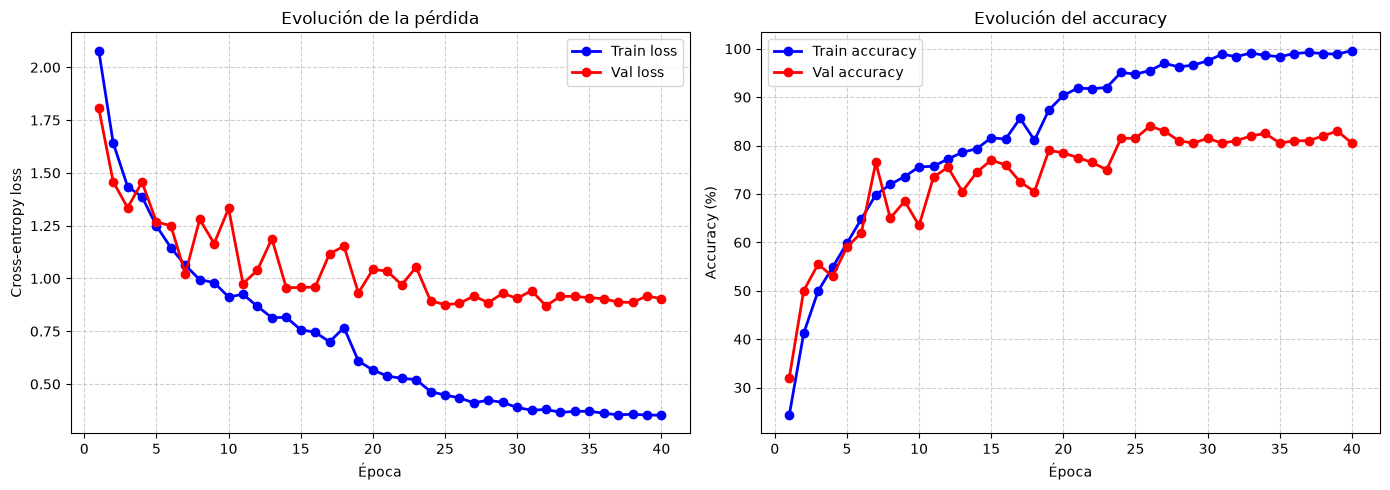

In [14]:
import matplotlib.pyplot as plt

if not train_loss_history:
    raise RuntimeError("Ejecutá primero la celda de entrenamiento para generar el historial.")

epochs = range(1, len(train_loss_history) + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, train_loss_history, 'b-o', label='Train loss', linewidth=2)
axes[0].plot(epochs, val_loss_history, 'r-o', label='Val loss', linewidth=2)
axes[0].set_title('Evolución de la pérdida')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Cross-entropy loss')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

axes[1].plot(epochs, train_acc_history, 'b-o', label='Train accuracy', linewidth=2)
axes[1].plot(epochs, val_acc_history, 'r-o', label='Val accuracy', linewidth=2)
axes[1].set_title('Evolución del accuracy')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Accuracy (%)')
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

🔄 Cargando los mejores pesos del modelo guardados ('mejor_modelo_crnn.pth')...
⏳ Evaluando el set de validación (esto puede tomar un momento en CPU)...

🎯 Precisión Total en Validación: 84.00% (168/200 canciones correctas)

📊 DETALLE DE CANCIONES Y SUS GRÁFICOS DE ATENCIÓN:

🎵 Canción 1:
   • Género Real:    classical
   • Género Predicho: classical
   • Resultado:      ¡Correcto! ✅


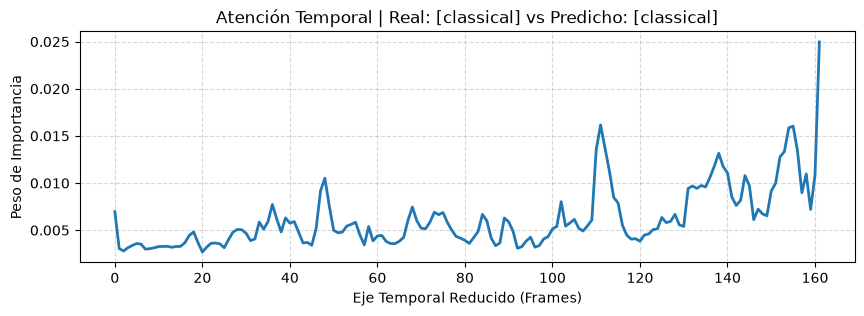


🎵 Canción 2:
   • Género Real:    blues
   • Género Predicho: blues
   • Resultado:      ¡Correcto! ✅


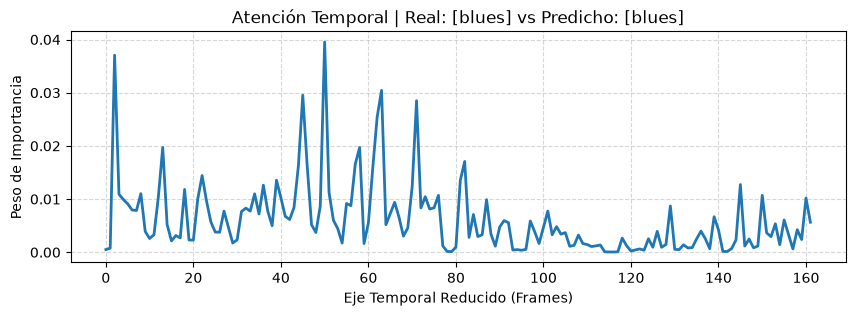


🎵 Canción 3:
   • Género Real:    metal
   • Género Predicho: metal
   • Resultado:      ¡Correcto! ✅


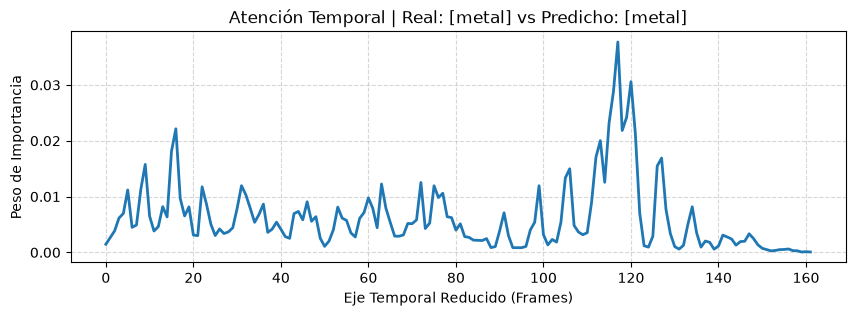


🎵 Canción 4:
   • Género Real:    jazz
   • Género Predicho: jazz
   • Resultado:      ¡Correcto! ✅


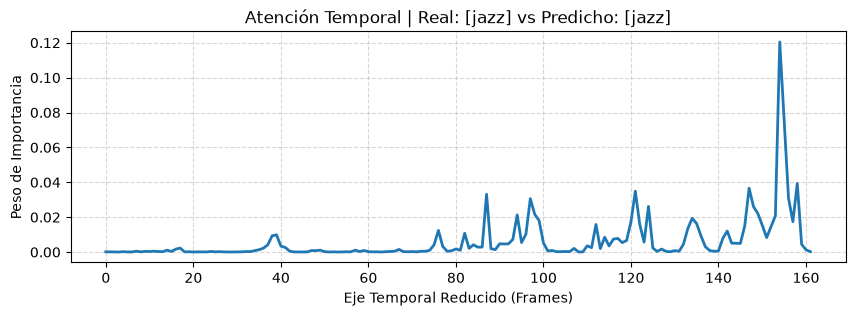


🎵 Canción 5:
   • Género Real:    blues
   • Género Predicho: blues
   • Resultado:      ¡Correcto! ✅


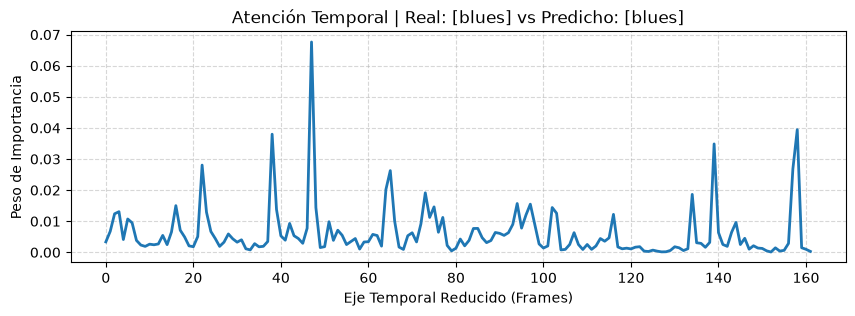


🎵 Canción 6:
   • Género Real:    country
   • Género Predicho: country
   • Resultado:      ¡Correcto! ✅


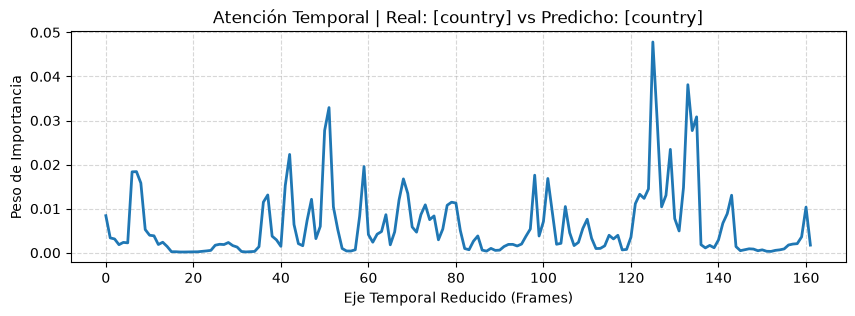


🎵 Canción 7:
   • Género Real:    rock
   • Género Predicho: rock
   • Resultado:      ¡Correcto! ✅


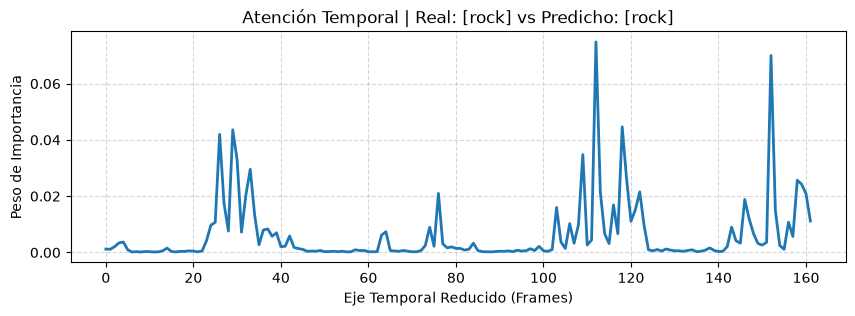


🎵 Canción 8:
   • Género Real:    country
   • Género Predicho: country
   • Resultado:      ¡Correcto! ✅


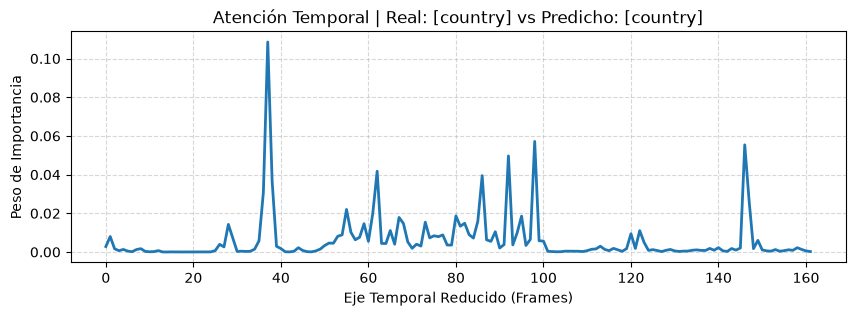

In [15]:
import matplotlib.pyplot as plt
import torch
import os

# Intentar cargar los mejores pesos guardados durante el entrenamiento
if os.path.exists("mejor_modelo_crnn.pth"):
    print("🔄 Cargando los mejores pesos del modelo guardados ('mejor_modelo_crnn.pth')...")
    try:
        model.load_state_dict(torch.load("mejor_modelo_crnn.pth", map_location=device))
    except RuntimeError:
        print("⚠️ El checkpoint corresponde a una arquitectura anterior. Entrená el modelo actual antes de evaluarlo.")
else:
    print("⚠️ No se encontró 'mejor_modelo_crnn.pth', se usará el estado actual del modelo.")

model.eval()
correct = 0
total = 0

# --- 1. EVALUACIÓN GLOBAL (Precisión en todo el set de validación) ---
print("⏳ Evaluando el set de validación (esto puede tomar un momento en CPU)...\n")
with torch.no_grad():
    for mel_inputs, cc_inputs, labels in val_loader:
        mel_inputs = mel_inputs.to(device)
        cc_inputs = cc_inputs.to(device)
        labels = labels.to(device)
        outputs, _ = model(mel_inputs, cc_inputs)

        # Obtener la clase predicha (la de mayor probabilidad)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"🎯 Precisión Total en Validación: {accuracy:.2f}% ({correct}/{total} canciones correctas)\n")
print("="*50)
print("📊 DETALLE DE CANCIONES Y SUS GRÁFICOS DE ATENCIÓN:")
print("="*50)

# --- 2. EVALUACIÓN DETALLADA Y VISUAL (Primer batch de validación) ---
with torch.no_grad():
    for mel_inputs, cc_inputs, labels in val_loader:
        mel_inputs = mel_inputs.to(device)
        cc_inputs = cc_inputs.to(device)
        labels = labels.to(device)
        outputs, attention_weights = model(mel_inputs, cc_inputs)

        _, predicted = torch.max(outputs, 1)

        # Iterar sobre las canciones de este batch
        for i in range(mel_inputs.size(0)):
            pred_idx = predicted[i].item()
            true_idx = labels[i].item()

            # Traducir índices a nombres de géneros
            pred_genre = class_names[pred_idx]
            true_genre = class_names[true_idx]

            print(f"\n🎵 Canción {i+1}:")
            print(f"   • Género Real:    {true_genre}")
            print(f"   • Género Predicho: {pred_genre}")

            if pred_idx == true_idx:
                print("   • Resultado:      ¡Correcto! ✅")
            else:
                print("   • Resultado:      Incorrecto ❌")

            # attention_weights tiene forma [Batch, Reduced_Time, 1]
            weights_np = attention_weights[i].cpu().squeeze().numpy()

            # Graficar los momentos a los que la red prestó atención
            plt.figure(figsize=(10, 3))
            plt.plot(weights_np, color='tab:blue', linewidth=2)
            plt.title(f"Atención Temporal | Real: [{true_genre}] vs Predicho: [{pred_genre}]")
            plt.xlabel("Eje Temporal Reducido (Frames)")
            plt.ylabel("Peso de Importancia")
            plt.grid(True, linestyle='--', alpha=0.5)
            plt.show()

        break  # Rompemos el loop para mostrar solo las canciones del primer batch

🔍 Buscando y analizando errores de clasificación en el conjunto de validación...



❌ Caso de Error #1:
   • Género Real:    HIPHOP
   • Género Predicho: DISCO


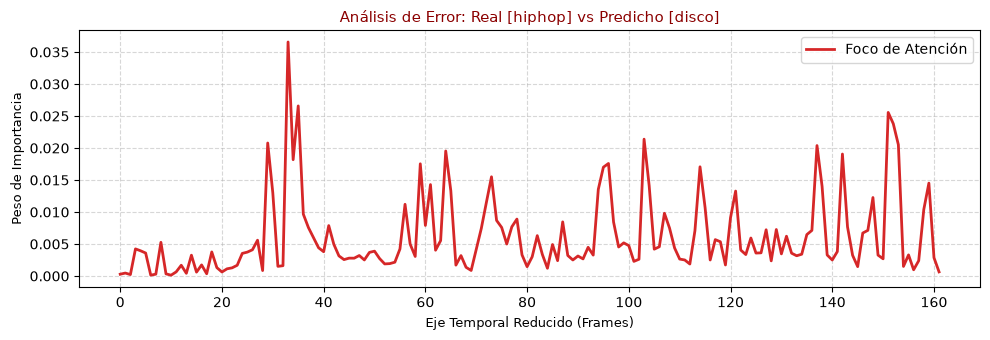

❌ Caso de Error #2:
   • Género Real:    DISCO
   • Género Predicho: HIPHOP


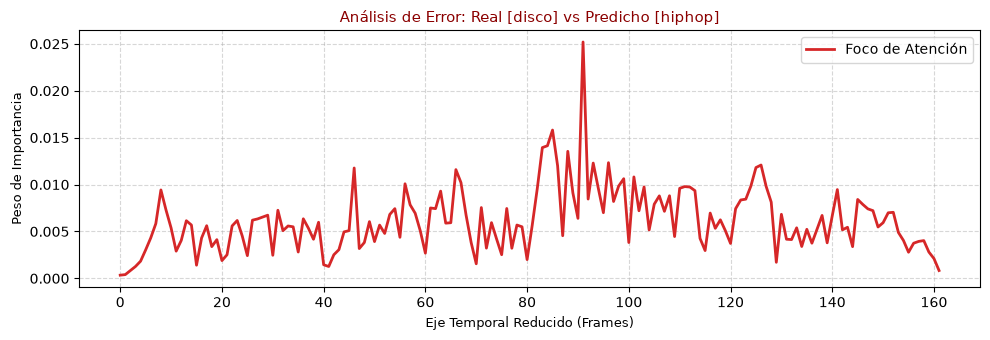

❌ Caso de Error #3:
   • Género Real:    ROCK
   • Género Predicho: COUNTRY


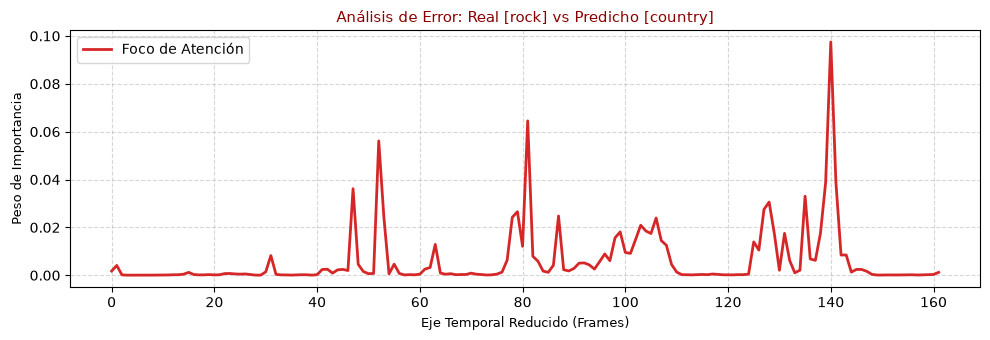

❌ Caso de Error #4:
   • Género Real:    COUNTRY
   • Género Predicho: ROCK


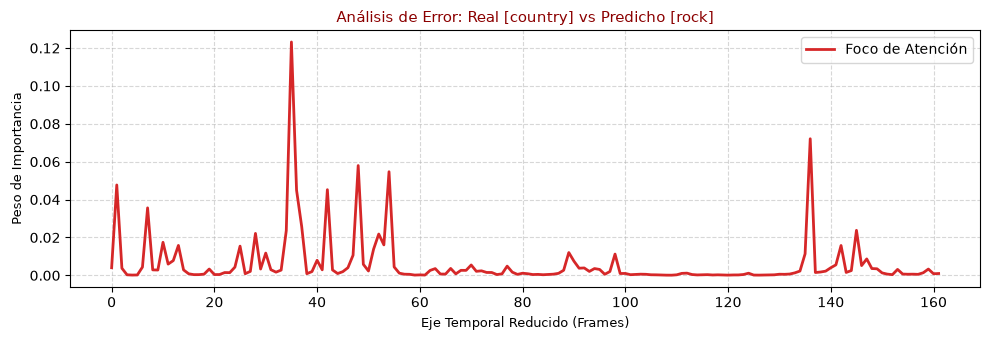

❌ Caso de Error #5:
   • Género Real:    REGGAE
   • Género Predicho: POP


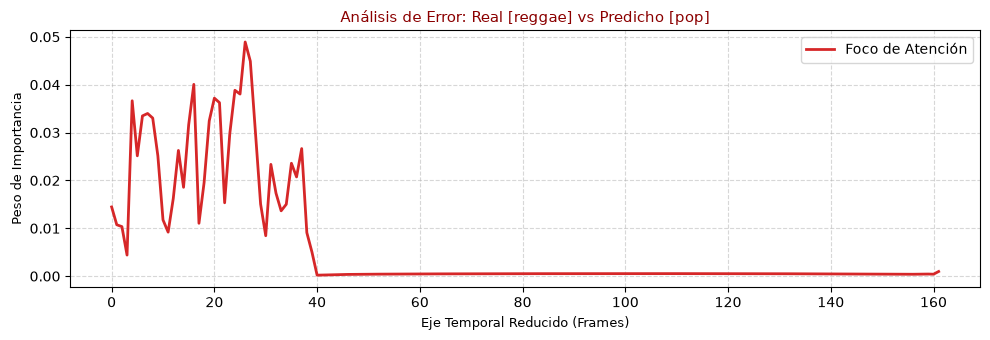

In [12]:
import matplotlib.pyplot as plt
import torch

model.eval()
error_count = 0
max_errors_to_show = 5

print("🔍 Buscando y analizando errores de clasificación en el conjunto de validación...\n")

with torch.no_grad():
    for mel_inputs, cc_inputs, labels in val_loader:
        mel_inputs = mel_inputs.to(device)
        cc_inputs = cc_inputs.to(device)
        labels = labels.to(device)
        outputs, attention_weights = model(mel_inputs, cc_inputs)

        _, predicted = torch.max(outputs, 1)

        for i in range(mel_inputs.size(0)):
            pred_idx = predicted[i].item()
            true_idx = labels[i].item()

            # Solo nos interesan las predicciones incorrectas
            if pred_idx != true_idx:
                error_count += 1
                pred_genre = class_names[pred_idx]
                true_genre = class_names[true_idx]

                print(f"❌ Caso de Error #{error_count}:")
                print(f"   • Género Real:    {true_genre.upper()}")
                print(f"   • Género Predicho: {pred_genre.upper()}")

                # Extraer pesos de atención para este audio específico
                weights_np = attention_weights[i].cpu().squeeze().numpy()

                # Graficar curva de atención temporal
                plt.figure(figsize=(10, 3.5))
                plt.plot(weights_np, color='tab:red', linewidth=2, label='Foco de Atención')
                plt.title(f"Análisis de Error: Real [{true_genre}] vs Predicho [{pred_genre}]", fontsize=11, color='darkred')
                plt.xlabel("Eje Temporal Reducido (Frames)", fontsize=9)
                plt.ylabel("Peso de Importancia", fontsize=9)
                plt.grid(True, linestyle='--', alpha=0.5)
                plt.legend()
                plt.tight_layout()
                plt.show()

                if error_count >= max_errors_to_show:
                    break
        if error_count >= max_errors_to_show:
            break

if error_count == 0:
    print("🎉 ¡Increíble! El modelo clasificó correctamente todas las canciones de este lote.")

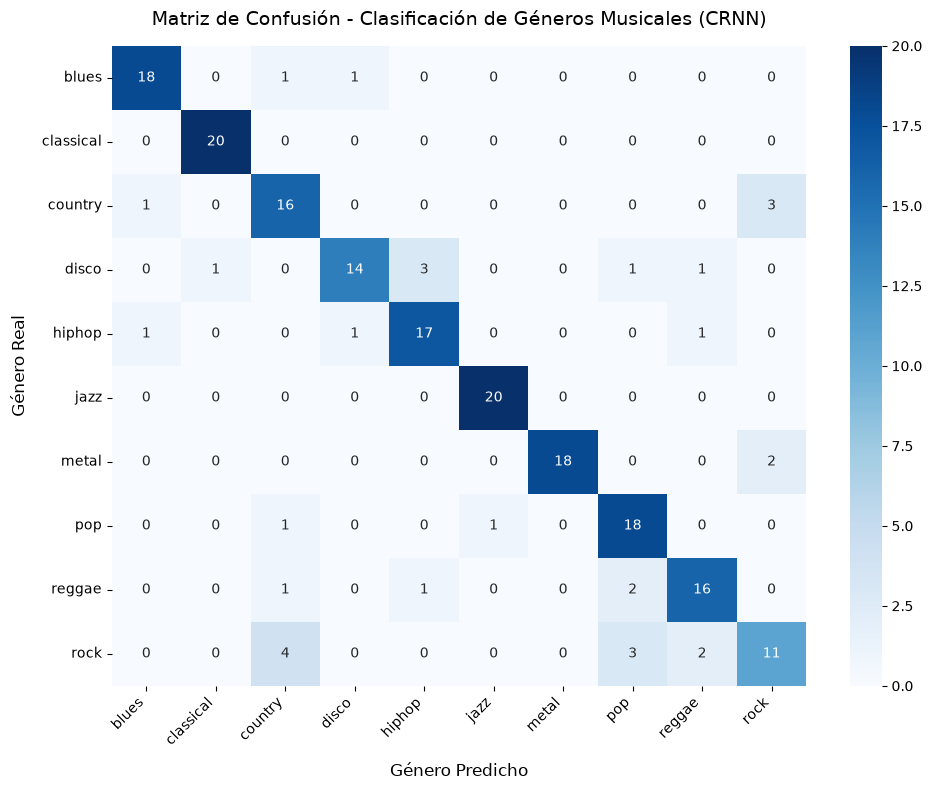

In [16]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
import numpy as np

model.eval()
true_labels = []
pred_labels = []

# Obtener predicciones en el set de validación
with torch.no_grad():
    for mel_inputs, cc_inputs, labels in val_loader:
        mel_inputs = mel_inputs.to(device)
        cc_inputs = cc_inputs.to(device)
        outputs, _ = model(mel_inputs, cc_inputs)
        _, predicted = torch.max(outputs, 1)

        true_labels.extend(labels.numpy())
        pred_labels.extend(predicted.cpu().numpy())

# Calcular la matriz de confusión
cm = confusion_matrix(true_labels, pred_labels)

# Graficar
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Matriz de Confusión - Clasificación de Géneros Musicales (CRNN)", fontsize=14, pad=15)
plt.xlabel("Género Predicho", fontsize=12, labelpad=10)
plt.ylabel("Género Real", fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()